# Experiment 4: Text Mining and Accessing a Text Corpus

**Name:** Rudra Gupta  
**SAP ID:** 500120437

**Aim:**
1. Calculate the word count of a specific document, show the top 10 frequent words with their frequency, and create a word cloud.
2. Study and implementation of Named Entity Recognition (NER).

**Document:** Barack Obama's 2009 inaugural address from NLTK's **Inaugural Address corpus**, saved as `document.txt` in this folder.

## Step 1: Install and import the required packages

In [1]:
%pip install nltk spacy pandas matplotlib wordcloud --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import pandas as pd
import nltk
import spacy
from spacy import displacy

for pkg in ["inaugural", "punkt", "punkt_tab", "stopwords", "averaged_perceptron_tagger_eng",
            "maxent_ne_chunker_tab", "words"]:
    nltk.download(pkg, quiet=True)

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    spacy.cli.download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")

### Chart style

In [3]:
import matplotlib.pyplot as plt

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e8e7e3"
BLUE, BLUE_LIGHT, MUTED = "#2a78d6", "#9ec5f4", "#8a8984"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 11, "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 28,
    "figure.dpi": 110,
})


def titles(ax, title, subtitle=None):
    ax.set_title(title, color=INK)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 7),
                    textcoords="offset points", color=INK2, fontsize=10.5, va="bottom")


def hbar(ax, labels, values, color=BLUE, fmt="{:,.0f}", highlight=None, highlight_color=BLUE):
    """Horizontal bars, largest at the top, with the value printed at the end of each bar."""
    labels, values = list(labels)[::-1], list(values)[::-1]
    colors = [highlight_color if l == highlight else color for l in labels]
    bars = ax.barh(labels, values, color=colors, height=0.68, edgecolor=SURFACE, linewidth=2)
    vmax = max(values)
    for b, v in zip(bars, values):
        ax.text(b.get_width() + vmax * 0.012, b.get_y() + b.get_height() / 2, fmt.format(v),
                va="center", fontsize=10, color=INK, zorder=4,
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
    ax.set_xlim(0, vmax * 1.14)
    ax.xaxis.set_visible(False)
    ax.spines[["bottom", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=10.5, labelcolor=INK)

# Part 1: Text mining on a document from a text corpus

## 1.1 Access the corpus and save the document
NLTK corpora are split into files (`fileids()`) that can be read as raw text (`raw()`), words (`words()`) or sentences (`sents()`).

In [4]:
from nltk.corpus import inaugural

print("Files in the inaugural corpus:", len(inaugural.fileids()))
print(inaugural.fileids()[:4], "...", inaugural.fileids()[-3:])

DOC_ID = "2009-Obama.txt"
with open("document.txt", "w", encoding="utf-8") as f:
    f.write(inaugural.raw(DOC_ID))

with open("document.txt", encoding="utf-8") as f:
    text = f.read()
print()
print(text[:500], "...")

Files in the inaugural corpus: 60
['1789-Washington.txt', '1793-Washington.txt', '1797-Adams.txt', '1801-Jefferson.txt'] ... ['2017-Trump.txt', '2021-Biden.txt', '2025-Trump.txt']

My fellow citizens:

I stand here today humbled by the task before us, grateful for the trust you have bestowed, mindful of the sacrifices borne by our ancestors. I thank President Bush for his service to our nation, as well as the generosity and cooperation he has shown throughout this transition.

Forty-four Americans have now taken the presidential oath. The words have been spoken during rising tides of prosperity and the still waters of peace. Yet, every so often the oath is taken amidst gat ...


## 1.2 Word count

In [5]:
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords

words = [t.lower() for t in word_tokenize(text) if t.isalpha()]

pd.DataFrame({"Value": {
    "Word count": len(words),
    "Unique words": len(set(words)),
    "Sentences": len(sent_tokenize(text)),
    "Characters": len(text),
}})

,Value
Word count,2385
Unique words,876
Sentences,110
Characters,13439


## 1.3 Top 10 frequent words
Stop words (*the, and, of ...*) would fill the top of the list, so they are removed first. NLTK's list is extended with a few filler words common in speeches (*us, let, upon, shall, may, also, yet*).

In [6]:
from nltk import FreqDist

stop_words = set(stopwords.words("english")) | {"us", "let", "upon", "shall", "may", "also", "yet"}
content_words = [w for w in words if w not in stop_words]
fd = FreqDist(content_words)

top10 = pd.DataFrame(fd.most_common(10), columns=["Word", "Frequency"])
top10.index = range(1, 11)
top10

,Word,Frequency
1,nation,12
2,new,11
3,america,10
4,every,8
5,must,8
6,people,7
7,less,7
8,world,7
9,today,6
10,time,6


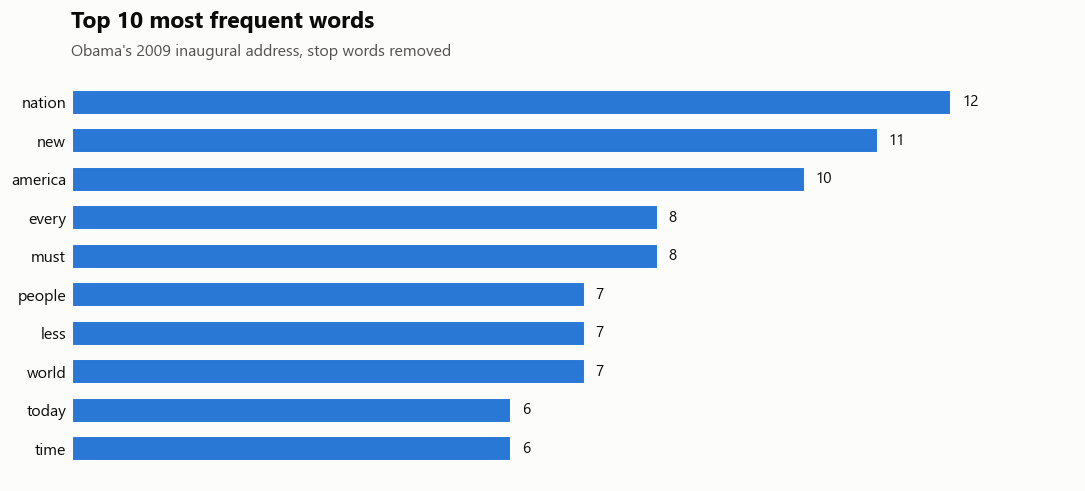

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.6))
hbar(ax, top10["Word"], top10["Frequency"])
titles(ax, "Top 10 most frequent words", "Obama's 2009 inaugural address, stop words removed")
plt.tight_layout()
plt.show()

## 1.4 Word cloud
Each word's size is proportional to its frequency.

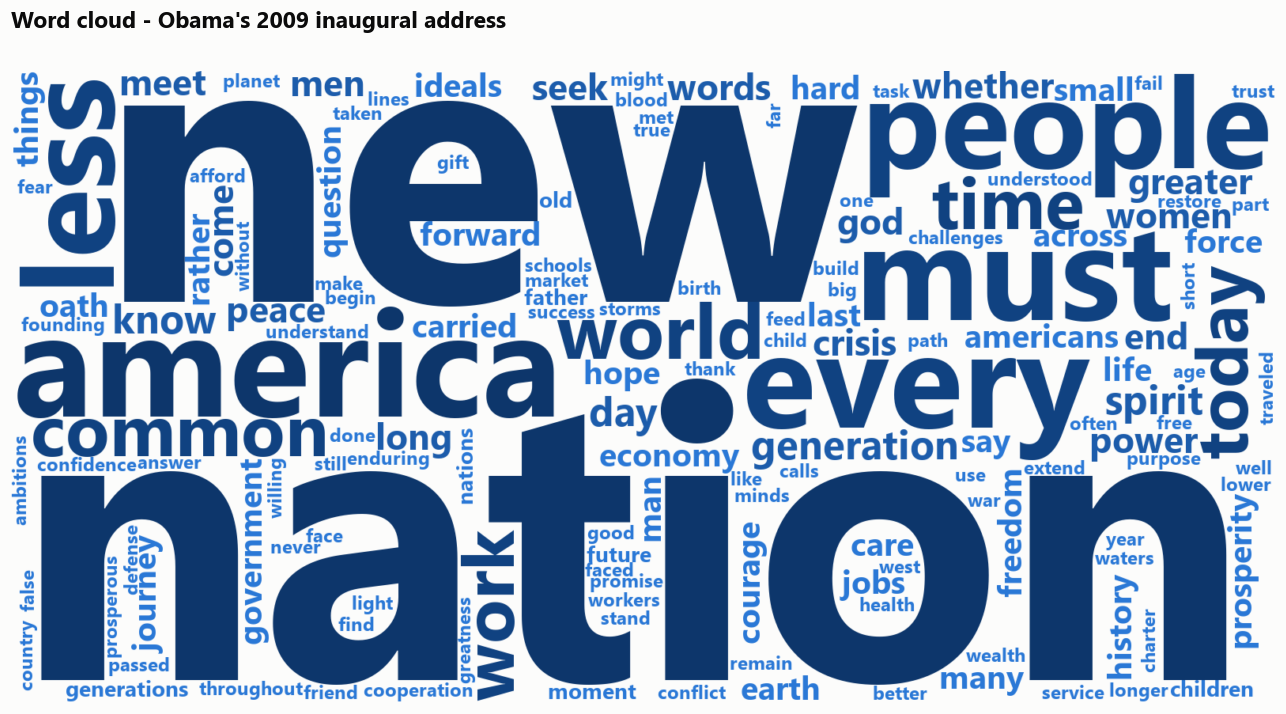

In [8]:
from wordcloud import WordCloud

RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
fmax = max(fd.values())
FONT = "C:/Windows/Fonts/segoeuib.ttf"

wc = WordCloud(width=1600, height=800, background_color=SURFACE, max_words=150, relative_scaling=0.45,
               color_func=lambda w, **kw: RAMP[round((fd[w] / fmax) ** 0.5 * (len(RAMP) - 1))],
               font_path=FONT if os.path.exists(FONT) else None, random_state=11).generate_from_frequencies(fd)

fig, ax = plt.subplots(figsize=(13, 6.6))
ax.imshow(wc, interpolation="bilinear")
ax.set_axis_off()
titles(ax, "Word cloud - Obama's 2009 inaugural address")
plt.tight_layout()
plt.show()

# Part 2: Named Entity Recognition (NER)

NER finds names of real-world things in text and labels each with a type.

| Label | Meaning | Examples |
|---|---|---|
| PERSON | people | *Sundar Pichai, Lionel Messi* |
| ORG | organisations | *Google, ISRO* |
| GPE | countries, cities, states | *India, Qatar, California* |
| LOC | other locations | *the Moon* |
| NORP | nationalities, religious or political groups | *Indian, Americans* |
| DATE / TIME | dates and times | *July 2020, 1976* |
| MONEY / CARDINAL | amounts and numbers | *$10 billion, millions* |
| EVENT / FAC / PRODUCT | events, buildings, products | *World Cup, Taj Mahal* |

We implement NER with two tools: NLTK's `ne_chunk` (a classic classifier over POS tags) and spaCy (a neural model).

In [9]:
sample = ("In July 2020, Google CEO Sundar Pichai announced a $10 billion fund to speed up the growth of "
          "India's digital economy. On 23 August 2023, the Indian Space Research Organisation (ISRO) landed "
          "Chandrayaan-3 near the south pole of the Moon. Lionel Messi led Argentina to victory at the 2022 "
          "FIFA World Cup in Qatar. Apple was founded by Steve Jobs and Steve Wozniak in 1976 in Cupertino, "
          "California. Every year, millions of tourists visit the Taj Mahal in Agra.")
print(sample)

In July 2020, Google CEO Sundar Pichai announced a $10 billion fund to speed up the growth of India's digital economy. On 23 August 2023, the Indian Space Research Organisation (ISRO) landed Chandrayaan-3 near the south pole of the Moon. Lionel Messi led Argentina to victory at the 2022 FIFA World Cup in Qatar. Apple was founded by Steve Jobs and Steve Wozniak in 1976 in Cupertino, California. Every year, millions of tourists visit the Taj Mahal in Agra.


## 2.1 NER with NLTK
Pipeline: tokenize -> POS tag -> `ne_chunk`, which returns a tree with each entity as a labelled subtree.

In [10]:
from nltk import ne_chunk, pos_tag

tree = ne_chunk(pos_tag(word_tokenize(sample)))
nltk_ents = [(" ".join(w for w, _ in st.leaves()), st.label()) for st in tree if hasattr(st, "label")]
pd.DataFrame(nltk_ents, columns=["Entity", "NLTK label"])

,Entity,NLTK label
0,Google CEO Sundar Pichai,PERSON
1,India,GPE
2,Indian,GPE
3,Space Research Organisation,ORGANIZATION
4,ISRO,ORGANIZATION
5,Moon,ORGANIZATION
6,Lionel Messi,PERSON
7,Argentina,GPE
8,FIFA,ORGANIZATION
9,Qatar,GPE


## 2.2 NER with spaCy

In [11]:
doc = nlp(sample)
displacy.render(doc, style="ent", jupyter=True)
pd.DataFrame([(e.text, e.label_, spacy.explain(e.label_)) for e in doc.ents],
             columns=["Entity", "spaCy label", "Meaning"])

,Entity,spaCy label,Meaning
0,July 2020,DATE,Absolute or relative dates or periods
1,Google,ORG,"Companies, agencies, institutions, etc."
2,Sundar Pichai,PERSON,"People, including fictional"
3,$10 billion,MONEY,"Monetary values, including unit"
4,India,GPE,"Countries, cities, states"
5,23 August 2023,DATE,Absolute or relative dates or periods
6,the Indian Space Research Organisation,ORG,"Companies, agencies, institutions, etc."
7,ISRO,ORG,"Companies, agencies, institutions, etc."
8,Moon,PERSON,"People, including fictional"
9,Lionel Messi,PERSON,"People, including fictional"


**NLTK vs spaCy:** NLTK only knows PERSON, ORGANIZATION, GPE, LOCATION and FACILITY, so it misses all dates, money and numbers; it also merges *Google CEO Sundar Pichai* into one PERSON and labels *Apple* as a PERSON. spaCy recognises many more types and draws entity boundaries more accurately.

## 2.3 NER on the document

In [12]:
speech = nlp(" ".join(text.split()))
ents = pd.DataFrame([(e.text, e.label_) for e in speech.ents], columns=["Entity", "Label"])
print(f"{len(ents)} entity mentions found")

summary = (ents.groupby("Label")["Entity"]
           .agg(Mentions="count", Examples=lambda s: ", ".join(s.value_counts().index[:6]))
           .sort_values("Mentions", ascending=False))
summary.insert(0, "Meaning", summary.index.map(spacy.explain))
summary

56 entity mentions found


,Meaning,Mentions,Examples
Label,,,
DATE,Absolute or relative dates or periods,18,"today, this day, each day, Today, last week, l..."
GPE,"Countries, cities, states",14,"America, Concord, Gettysburg, Iraq, Afghanista..."
NORP,Nationalities or religious or political groups,11,"Americans, American, Christians, Muslims, Jews..."
LOC,"Non-GPE locations, mountain ranges, bodies of ...",4,"West, Earth"
PERSON,"People, including fictional",4,"Bush, Normandy, Khe Sahn, God"
TIME,Times smaller than a day,3,"this very hour, hours, our darkest hours"
CARDINAL,Numerals that do not fall under another type,2,"Forty-four, one"


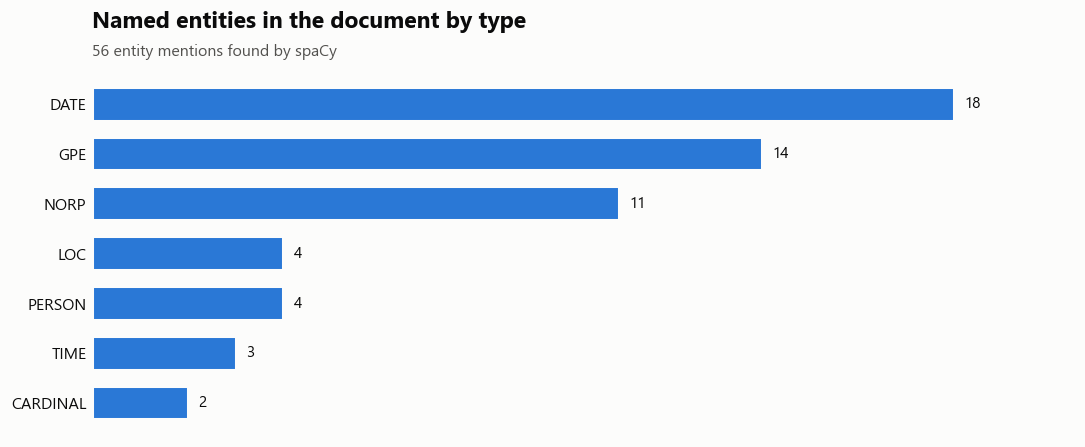

In [13]:
counts = summary["Mentions"]
fig, ax = plt.subplots(figsize=(10, 4.2))
hbar(ax, counts.index, counts.values)
titles(ax, "Named entities in the document by type", f"{len(ents)} entity mentions found by spaCy")
plt.tight_layout()
plt.show()

## Conclusion
**Part 1:** We accessed NLTK's Inaugural Address corpus, saved Obama's 2009 address to `document.txt`, counted its words, listed the 10 most frequent words (after removing stop words) with their frequencies, and drew a word cloud.

**Part 2:** We implemented NER with NLTK's `ne_chunk` and with spaCy on a sample text; spaCy found more entity types with more accurate boundaries. We then extracted and counted the named entities in the inaugural address.